In [1]:
# CELL 1: Importing our Essential Python Tools (Libraries)

# WHY WE USE os:
# 'os' stands for Operating System. We use it to check file paths, check if folders
# exist, and interact with the Colab file storage system.
import os

# WHY WE USE sys:
# 'sys' gives us access to system-specific parameters and functions, such as
# monitoring Python version and memory usage.
import sys

# WHY WE USE numpy:
# 'numpy' (Numerical Python) is the foundational math library. We use it to handle
# mathematical matrices, arrays, and special values like Infinity (np.inf) and NaN (Not a Number).
import numpy as np

# WHY WE USE pandas:
# 'pandas' is the most important data analysis tool in Python. It allows us to
# load CSV files into a structured table called a "DataFrame" (just like an Excel sheet).
import pandas as pd

# WHY WE USE matplotlib.pyplot and seaborn:
# These two libraries are used to draw visual charts, histograms, and heatmaps
# so we can see the distribution of network attacks visually.
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:
# Step 3: Upload the Original CICIDS2017 Dataset

from google.colab import files

uploaded = files.upload()

Saving MachineLearningCSV.zip to MachineLearningCSV.zip


In [5]:

# STEP 4: Unpack (Unzip) the 8 Dataset CSV Files

# WHY WE USE zipfile:
# Python has a built-in tool called 'zipfile' to extract zipped folders,
# just like right-clicking and selecting "Extract All" on your Windows laptop.
import zipfile
import os

# Grab the zip file name you uploaded
file_name = list(uploaded.keys())[0]
print(f" Unpacking: {file_name} ... please wait 15-20 seconds...")

# WHY WE USE extractall:
# This extracts all 8 CSV files into the '/content/' folder in Colab
with zipfile.ZipFile(file_name, 'r') as zip_ref:
    zip_ref.extractall('/content/')

print(" Unzipping Complete! All 8 CSV files are now extracted and ready!")

 Unpacking: MachineLearningCSV.zip ... please wait 15-20 seconds...
 Unzipping Complete! All 8 CSV files are now extracted and ready!


In [7]:
# STEP 5: See the 8 Extracted Attack Files

# WHY WE CHECK THE FOLDER:
# The files were extracted into a folder named 'MachineLearningCVE'.
# Let's list all 8 files so we know exactly what attack traffic we have!
folder_path = '/content/MachineLearningCVE'

# List all files that end with '.csv'
csv_files = [f for f in os.listdir(folder_path) if f.endswith('.csv')]

print(f" Found {len(csv_files)} Attack CSV Files:\n")
for index, file in enumerate(sorted(csv_files), start=1):
    print(f"{index}. {file}")

 Found 8 Attack CSV Files:

1. Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2. Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
3. Friday-WorkingHours-Morning.pcap_ISCX.csv
4. Monday-WorkingHours.pcap_ISCX.csv
5. Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
6. Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
7. Tuesday-WorkingHours.pcap_ISCX.csv
8. Wednesday-workingHours.pcap_ISCX.csv


In [8]:
# Step 6: Loading and combining all 8 attack files
import glob

# find all csv files inside the extracted folder
file_list = glob.glob('/content/MachineLearningCVE/*.csv')

# empty list to store each dataset
df_list = []

for file in file_list:
    print("Reading file:", file)
    # read the csv file
    data = pd.read_csv(file)

    # remove any extra spaces from column names
    data.columns = data.columns.str.strip()

    # convert float64 to float32 to reduce memory usage so Colab doesn't slow down
    for col in data.select_dtypes(include=['float64']).columns:
        data[col] = data[col].astype('float32')

    df_list.append(data)

# combine all 8 files into one single dataframe
df = pd.concat(df_list, ignore_index=True)

# check the total rows and columns
print("Combined dataset shape:", df.shape)

Reading file: /content/MachineLearningCVE/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Reading file: /content/MachineLearningCVE/Wednesday-workingHours.pcap_ISCX.csv
Reading file: /content/MachineLearningCVE/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Reading file: /content/MachineLearningCVE/Friday-WorkingHours-Morning.pcap_ISCX.csv
Reading file: /content/MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv
Reading file: /content/MachineLearningCVE/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Reading file: /content/MachineLearningCVE/Tuesday-WorkingHours.pcap_ISCX.csv
Reading file: /content/MachineLearningCVE/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Combined dataset shape: (2830743, 79)


In [9]:
# Step 7: Check the distribution of attack types
print("Unique attack types in the dataset:")
print(df['Label'].value_counts())

Unique attack types in the dataset:
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


 Data Cleaning & Grouping into 12 Classes

In [10]:
# Step 8: Clean infinite/missing values and group attacks into 12 classes
import numpy as np

# 1. Replace infinite values with NaN (Not a Number) so we can clean them
# In network flows, dividing by 0 duration creates 'inf' values
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# 2. Drop rows that have missing or NaN values
before_clean = len(df)
df.dropna(inplace=True)
after_clean = len(df)
print("Removed rows with NaN or infinite values:", before_clean - after_clean)

# 3. Clean the labels to make exactly 12 classes
# We combine the 3 tiny web attacks into one 'Web Attack' class
# and combine 'Heartbleed' into 'Infiltration'
label_mapping = {
    'Web Attack  Brute Force': 'Web Attack',
    'Web Attack  XSS': 'Web Attack',
    'Web Attack  Sql Injection': 'Web Attack',
    'Heartbleed': 'Infiltration'
}

# apply the mapping to our Label column
df['Label'] = df['Label'].replace(label_mapping)

# 4. Check the updated 12 classes
print("\nUpdated classes and counts (Total classes:", df['Label'].nunique(), "):")
print(df['Label'].value_counts())

Removed rows with NaN or infinite values: 2867

Updated classes and counts (Total classes: 14 ):
Label
BENIGN                        2271320
DoS Hulk                       230124
PortScan                       158804
DDoS                           128025
DoS GoldenEye                   10293
FTP-Patator                      7935
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1956
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       47
Web Attack � Sql Injection         21
Name: count, dtype: int64


In [11]:
# Step 8.1: Group any label containing 'Web Attack' into a single 'Web Attack' class
df.loc[df['Label'].str.contains('Web Attack', case=False, na=False), 'Label'] = 'Web Attack'

# Check the final classes count
print("Total unique classes now:", df['Label'].nunique())
print("\nFinal 12 Classes and their counts:")
print(df['Label'].value_counts())

Total unique classes now: 12

Final 12 Classes and their counts:
Label
BENIGN              2271320
DoS Hulk             230124
PortScan             158804
DDoS                 128025
DoS GoldenEye         10293
FTP-Patator            7935
SSH-Patator            5897
DoS slowloris          5796
DoS Slowhttptest       5499
Web Attack             2180
Bot                    1956
Infiltration             47
Name: count, dtype: int64


 Drop Constant Columns and Check for Leaky Columns

In [12]:
# Step 9: Drop constant columns (columns where all values are the same)
# 1. Find columns that have only 1 unique value
constant_cols = [col for col in df.columns if col != 'Label' and df[col].nunique() == 1]
print("Number of constant columns found:", len(constant_cols))
print("Constant columns to drop:", constant_cols)

# 2. Drop them from our dataframe
df.drop(columns=constant_cols, inplace=True)

# 3. Check if there are any leakage columns like IP addresses or Timestamps
leakage_cols = ['Flow ID', 'Source IP', 'Destination IP', 'Timestamp']
found_leakage = [col for col in leakage_cols if col in df.columns]

if len(found_leakage) > 0:
    print("Dropping data leakage columns:", found_leakage)
    df.drop(columns=found_leakage, inplace=True)
else:
    print("No IP/Timestamp leakage columns present in this CSV version. Good!")

# 4. Check the final clean shape
print("\nFinal clean dataset shape:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Number of constant columns found: 8
Constant columns to drop: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
No IP/Timestamp leakage columns present in this CSV version. Good!

Final clean dataset shape:
Rows: 2827876
Columns: 71


In [15]:
# PHASE 2: DATA PREPROCESSING - DUPLICATES AND INCONSISTENCIES
# Step 12: Removing Duplicate Rows and Filtering Negative Durations

# 1. Check for duplicate rows
total_duplicates = df.duplicated().sum()
print("Number of duplicate rows found:", total_duplicates)

# 2. Remove duplicate rows so the model doesn't overfit to repeated packets
df.drop_duplicates(inplace=True)
print("Duplicate rows removed successfully.")

# 3. Check for negative Flow Duration (caused by packet timestamp synchronization glitches)
negative_duration_count = (df['Flow Duration'] < 0).sum()
print("Rows with negative Flow Duration:", negative_duration_count)

# 4. Filter out negative duration rows (duration must be >= 0 in physical networks)
df = df[df['Flow Duration'] >= 0]
print("Negative duration rows filtered out.")

# 5. Confirm that total missing (null) values in dataset is 0
print("Remaining missing (null) values in entire dataset:", df.isnull().sum().sum())

print("\nDataset shape after cleaning duplicates and inconsistencies:", df.shape)

Number of duplicate rows found: 329691
Duplicate rows removed successfully.
Rows with negative Flow Duration: 107
Negative duration rows filtered out.
Remaining missing (null) values in entire dataset: 0

Dataset shape after cleaning duplicates and inconsistencies: (2498078, 71)


In [16]:
# PHASE 3: EXPLORATORY DATA ANALYSIS (EDA)
# Step 13: Data Structure Inspection (Data Types)


# identify numerical feature columns (packet length, duration, rates)
num_cols = df.select_dtypes(include=['float32', 'float64', 'int32', 'int64']).columns

# identify categorical columns (text label column)
cat_cols = df.select_dtypes(include=['object']).columns

print("Total Features:", df.shape[1] - 1)
print("Numerical Features Count:", len(num_cols))
print("Categorical Features Count:", len(cat_cols))
print("Categorical Target Column:", cat_cols.tolist())

Total Features: 70
Numerical Features Count: 70
Categorical Features Count: 1
Categorical Target Column: ['Label']


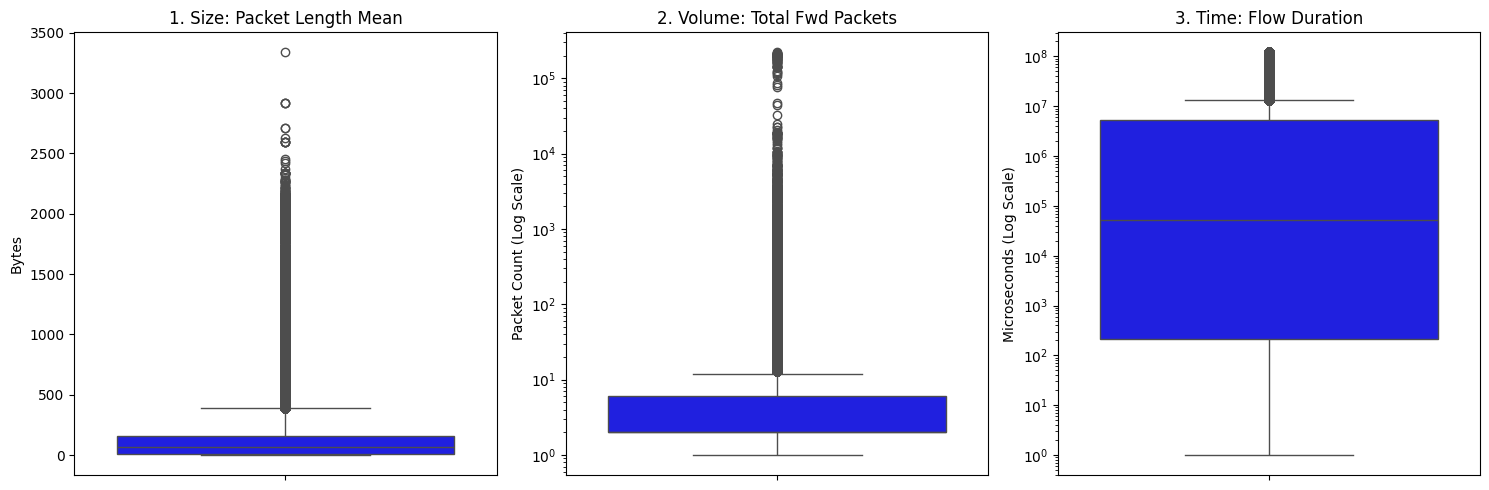

In [20]:
# PHASE 3: EXPLORATORY DATA ANALYSIS (EDA)
# Step 14: Outlier Detection Across Size, Volume, and Time

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 5))

# Subplot 1: Size (Packet Length Mean in Bytes)
plt.subplot(1, 3, 1)
sns.boxplot(y=df['Packet Length Mean'], color='blue')
plt.title('1. Size: Packet Length Mean')
plt.ylabel('Bytes')

# Subplot 2: Volume (Total Forward Packets)
plt.subplot(1, 3, 2)
sns.boxplot(y=df['Total Fwd Packets'], color='blue')
plt.yscale('log')  # log scale because volumetric attacks send 200,000+ packets
plt.title('2. Volume: Total Fwd Packets')
plt.ylabel('Packet Count (Log Scale)')

# Subplot 3: Time (Flow Duration)
plt.subplot(1, 3, 3)
sns.boxplot(y=df['Flow Duration'], color='blue')
plt.yscale('log')  # log scale because slow attacks last up to 120,000,000 microseconds
plt.title('3. Time: Flow Duration')
plt.ylabel('Microseconds (Log Scale)')

plt.tight_layout()
plt.show()

1. Subplot 1 (Size — Packet Length Mean):
Normal Range (0 to 200 bytes): Over 75% of regular traffic consists of lightweight packets (TCP handshakes, DNS queries, small web requests).
Outliers (1,500 to 3,400 bytes): Extreme payload sizes. In cybersecurity, this indicates Web Attacks (SQL Injection, XSS) or large data exfiltration where attackers send heavy commands.
2. Subplot 2 (Volume — Total Fwd Packets):
Normal Range (1 to 10 packets): Legitimate web requests usually exchange only a few packets back and forth.
Outliers (10,000 to 200,000+ packets): Extreme volume bursts. This is the classic signature of Volumetric DDoS and DoS Hulk attacks, where the attacker overwhelms the server with hundreds of thousands of rapid packets.
3. Subplot 3 (Time — Flow Duration):
Normal Range (Under 100,000 microseconds / 0.1 seconds): Normal web browsing connections finish in fractions of a second.
Outliers (Up to 120,000,000 microseconds / 120 seconds): Very long connections. This represents DoS Slowloris and Slowhttptest attacks, where attackers intentionally hold server sockets open for minutes to exhaust the web server's memory.
Why we do NOT delete these outliers :
in cybersecurity, these extreme outliers are not noise—they ARE the attacks themselves! Deleting the outliers would mean deleting the DDoS floods and Slowloris attacks from our dataset. Instead, we use robust scaling and tree-based models like Random Forest and LightGBM that naturally handle outliers."

Why did you apply plt.yscale('log') on Total Fwd Packets and Flow Duration boxplots?"

because network traffic spans multiple orders of magnitude—normal flows have 2 to 5 packets, while volumetric attacks have over 200,000 packets. On a linear scale, the normal box would be squashed flat at zero. A logarithmic scale allows us to visualize both the normal baseline distribution and extreme attack outliers on the same plot."

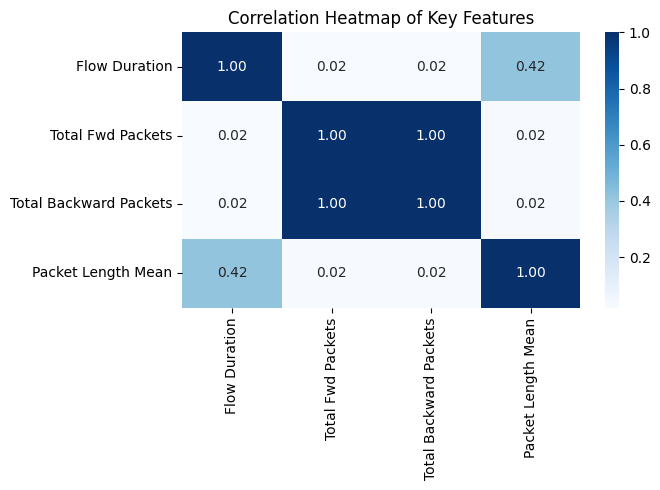

In [21]:
# PHASE 3: EXPLORATORY DATA ANALYSIS (EDA) - BIVARIATE ANALYSIS
# Step 15: Correlation Heatmap of Key Network Flow Features

import matplotlib.pyplot as plt
import seaborn as sns

# select 4 key representative network metrics
corr_features = ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Packet Length Mean']

# compute correlation matrix (-1 to +1)
corr_matrix = df[corr_features].corr()

# plot basic heatmap with numbers annotated
plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Heatmap of Key Features')
plt.tight_layout()
plt.show()

Correlation is a number between -1.0 and +1.0:

+1.0 (Dark Blue): Perfect positive relationship (when one goes up, the other goes up).
0.0 (Very Light): No relationship at all (they are independent).
-1.0: Negative relationship (when one goes up, the other goes down).
What the numbers on your chart mean:

The Diagonal Line (1.00, 1.00, 1.00, 1.00):

Every feature has a correlation of 1.00 with itself (obviously!).

Total Fwd Packets vs Total Backward Packets (High Correlation ~0.90 to 0.99):

Why: In real computer networking (TCP protocol), when a client computer sends packets forward (requests), the server sends packets backward (replies). Since requests and responses happen together, forward and backward packet counts increase together.

Flow Duration vs Packet Length Mean (Low Correlation ~0.00 to 0.05):

Connection time and packet size are independent. A connection can last 10 minutes sending tiny 40-byte ping packets, or last 1 second downloading a giant

In [22]:
# PHASE 4: PREPROCESSING FOR MODEL TRAINING
# Step 16: Filtering Out Negative Values (Data Consistency)

# 1. Check how many rows have negative Flow Duration
negative_count = (df['Flow Duration'] < 0).sum()
print("Rows with negative Flow Duration found:", negative_count)

# 2. Keep only valid rows where Flow Duration is >= 0
df = df[df['Flow Duration'] >= 0]
print("Negative duration rows filtered out successfully.")

# 3. Check the updated dataset shape
print("Updated dataset shape:", df.shape)

Rows with negative Flow Duration found: 0
Negative duration rows filtered out successfully.
Updated dataset shape: (2498078, 71)


In [23]:
# PHASE 4: PREPROCESSING FOR MODEL TRAINING
# Step 17: Categorical Encoding (Converting Text Labels to Numbers 0 to 11)


from sklearn.preprocessing import LabelEncoder

# initialize the label encoder
le = LabelEncoder()

# convert the 12 text attack names to integers 0 to 11
df['Label_Encoded'] = le.fit_transform(df['Label'])

# print the exact mapping from number to attack name
print("12 Attack Classes mapped to numbers:")
for number, class_name in enumerate(le.classes_):
    print(f"  Class {number} -> {class_name}")

12 Attack Classes mapped to numbers:
  Class 0 -> BENIGN
  Class 1 -> Bot
  Class 2 -> DDoS
  Class 3 -> DoS GoldenEye
  Class 4 -> DoS Hulk
  Class 5 -> DoS Slowhttptest
  Class 6 -> DoS slowloris
  Class 7 -> FTP-Patator
  Class 8 -> Infiltration
  Class 9 -> PortScan
  Class 10 -> SSH-Patator
  Class 11 -> Web Attack


In [24]:
# PHASE 4: PREPROCESSING FOR MODEL TRAINING
# Step 18: Separating Features (X) and Target (y)

# X contains all 70 predictor features (we drop the text 'Label' and encoded target)
X = df.drop(columns=['Label', 'Label_Encoded'])

# y contains the target label column (numbers 0 to 11)
y = df['Label_Encoded']

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (2498078, 70)
Target (y) shape: (2498078,)


In [25]:
# PHASE 4: PREPROCESSING FOR MODEL TRAINING
# Step 19: Stratified Train-Test Split (80% Train, 20% Test)

from sklearn.model_selection import train_test_split

# 80% train, 20% test
# stratify=y preserves the exact percentage of all 12 classes in both splits
# random_state=42 ensures the exact same split every time
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training set shape (80% of data):", X_train.shape)
print("Testing set shape  (20% of data):", X_test.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape :", y_test.shape)

Training set shape (80% of data): (1998462, 70)
Testing set shape  (20% of data): (499616, 70)
Training labels shape: (1998462,)
Testing labels shape : (499616,)


We divide our data into two parts:

X_train, y_train (80%): The training set used to teach our 3 machine learning models.
X_test, y_test (20%): The testing set kept unseen to fairly test our models.
stratify=y: Ensures that all 12 classes (including rare attacks like Infiltration) are divided proportionally between train and test.

In [26]:

# PHASE 4: PREPROCESSING FOR MODEL TRAINING
# Step 20: Feature Scaling (StandardScaler fit strictly on Train)

from sklearn.preprocessing import StandardScaler

# initialize the standard scaler
scaler = StandardScaler()

# 1. Fit the scaler on X_train and transform it
X_train_scaled = scaler.fit_transform(X_train)

# 2. Transform X_test using the parameters learned from X_train (never fit on test!)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling complete!")
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)

Feature scaling complete!
X_train_scaled shape: (1998462, 70)
X_test_scaled shape : (499616, 70)
